In [181]:
import pandas as pd
import numpy as  np
import math
import matplotlib.pyplot as plt
import seaborn as sns

In [182]:
df = pd.read_csv("Data/train.csv")

In [183]:
print(f"Rows:{df.shape[0]}\nColumns:{df.shape[1]}")

Rows:891
Columns:12


## Handling Consistency

In [184]:
# Null values
df = df.replace(['', 'NULL', 'null', 'NaN', 'nan','NAN',pd.NA, pd.NaT,None], np.nan) 

In [185]:
df.sample(5)

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
36,37,1,3,"Mamee, Mr. Hanna",male,NaN,0,0,2677,7.2292,NaN,C
232,233,0,2,"Sjostedt, Mr. Ernst Adolf",male,59.0,0,0,237442,13.5000,NaN,S
227,228,0,3,"Lovell, Mr. John Hall (""Henry"")",male,20.5,0,0,A/5 21173,7.2500,NaN,S
843,844,0,3,"Lemberopolous, Mr. Peter L",male,34.5,0,0,2683,6.4375,NaN,C
837,838,0,3,"Sirota, Mr. Maurice",male,NaN,0,0,392092,8.0500,NaN,S


## Initial Feature Handling

In [186]:
df['Cabin_Deck'] = df['Cabin'].str[0].fillna("NoCabin")
df['Name_Titles'] = df['Name'].str.split(",").str[1].str.split(".").str[0].str.strip()

In [187]:
dropped=['PassengerId','Ticket','Name','Cabin']
df.drop(columns=dropped, errors='ignore', inplace = True)

In [188]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 10 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   Survived     891 non-null    int64  
 1   Pclass       891 non-null    int64  
 2   Sex          891 non-null    object 
 3   Age          714 non-null    float64
 4   SibSp        891 non-null    int64  
 5   Parch        891 non-null    int64  
 6   Fare         891 non-null    float64
 7   Embarked     889 non-null    object 
 8   Cabin_Deck   891 non-null    object 
 9   Name_Titles  891 non-null    object 
dtypes: float64(2), int64(4), object(4)
memory usage: 69.7+ KB


## Column separation

In [189]:
def col_sep(dataframe):
    num_cols = dataframe.select_dtypes(include="number").columns.to_list()
    obj_cols = dataframe.select_dtypes(exclude="number").columns.to_list()
    return num_cols, obj_cols

In [190]:
num_cols, obj_cols = col_sep(df)

# EDA

In [191]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 10 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   Survived     891 non-null    int64  
 1   Pclass       891 non-null    int64  
 2   Sex          891 non-null    object 
 3   Age          714 non-null    float64
 4   SibSp        891 non-null    int64  
 5   Parch        891 non-null    int64  
 6   Fare         891 non-null    float64
 7   Embarked     889 non-null    object 
 8   Cabin_Deck   891 non-null    object 
 9   Name_Titles  891 non-null    object 
dtypes: float64(2), int64(4), object(4)
memory usage: 69.7+ KB


## Univariate Analysis

### Categorical data

In [192]:
obj_cols

['Sex', 'Embarked', 'Cabin_Deck', 'Name_Titles']

In [193]:
df.describe(exclude='number')

,Sex,Embarked,Cabin_Deck,Name_Titles
count,891,889,891,891
unique,2,3,9,17
top,male,S,NoCabin,Mr
freq,577,644,687,517


In [194]:
unique_vals = df[obj_cols].nunique()
unique_vals.sort_values(inplace=True)

binary_class = unique_vals[unique_vals == 2].index.tolist()
low_cardinality = unique_vals[unique_vals < 20].index.tolist()
high_cardinality = unique_vals[unique_vals >= 20].index.tolist()
    
print(unique_vals)

print("\nBinary class columns:", binary_class)
print("\nLow cardinality columns:", low_cardinality)
print("\nHigh cardinality columns:", high_cardinality)

Sex             2
Embarked        3
Cabin_Deck      9
Name_Titles    17
dtype: int64

Binary class columns: ['Sex']

Low cardinality columns: ['Sex', 'Embarked', 'Cabin_Deck', 'Name_Titles']

High cardinality columns: []


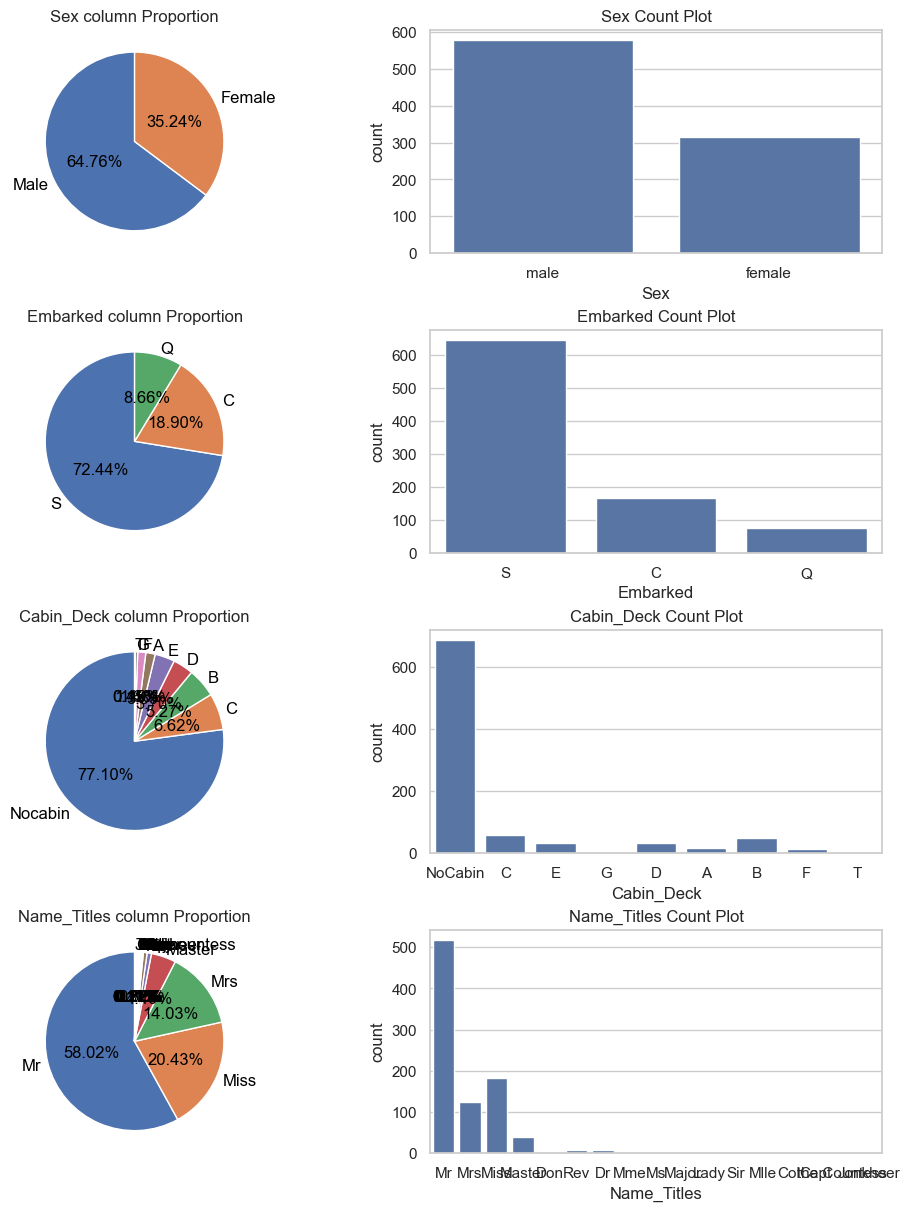

In [195]:
cols=2
l=len(low_cardinality)*2
rows=math.ceil(l/cols)


sns.set_theme(
    style="whitegrid",
    font_scale=1.0
)



fig, axs = plt.subplots(rows,
                        cols,
                        figsize=(cols*5,rows*3),
                        constrained_layout=True)



axs = np.atleast_1d(axs).flatten() 

x=0
for i in low_cardinality:
    
    percent = df[i].value_counts(normalize=True)*100

    labels=percent.index.astype(str).str.capitalize()
    


    axs[x].pie(
        percent,
        labels = labels,
        autopct = "%1.2f%%",
        startangle = 90,
        pctdistance = 0.5,
        labeldistance = 1.08,
        
        textprops={"fontsize":12, "color":"black"}
           )
    
    axs[x].set_title(f"{i} column Proportion")

    x=x+1
    
    sns.countplot(x=i,data=df,ax=axs[x])
    axs[x].set_title(f"{i} Count Plot")
    

    x+=1

for ax in axs[x:]:
    ax.axis("off") #ax assigns with graph space

### Numerical Data

In [196]:
num_cols

['Survived', 'Pclass', 'Age', 'SibSp', 'Parch', 'Fare']

In [197]:
Discrete = ['Pclass', 'SibSp', 'Parch']
Continuous = ['Age', 'Fare']

#### Discrete

In [198]:
print(df[Discrete].info())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 3 columns):
 #   Column  Non-Null Count  Dtype
---  ------  --------------  -----
 0   Pclass  891 non-null    int64
 1   SibSp   891 non-null    int64
 2   Parch   891 non-null    int64
dtypes: int64(3)
memory usage: 21.0 KB
None


In [199]:
print(df[Discrete].describe())

           Pclass       SibSp       Parch
count  891.000000  891.000000  891.000000
mean     2.308642    0.523008    0.381594
std      0.836071    1.102743    0.806057
min      1.000000    0.000000    0.000000
25%      2.000000    0.000000    0.000000
50%      3.000000    0.000000    0.000000
75%      3.000000    1.000000    0.000000
max      3.000000    8.000000    6.000000


In [200]:
Dcols = df[Discrete].nunique()
Dcols = Dcols[Dcols <= 20].index
Dcols

Index(['Pclass', 'SibSp', 'Parch'], dtype='object')

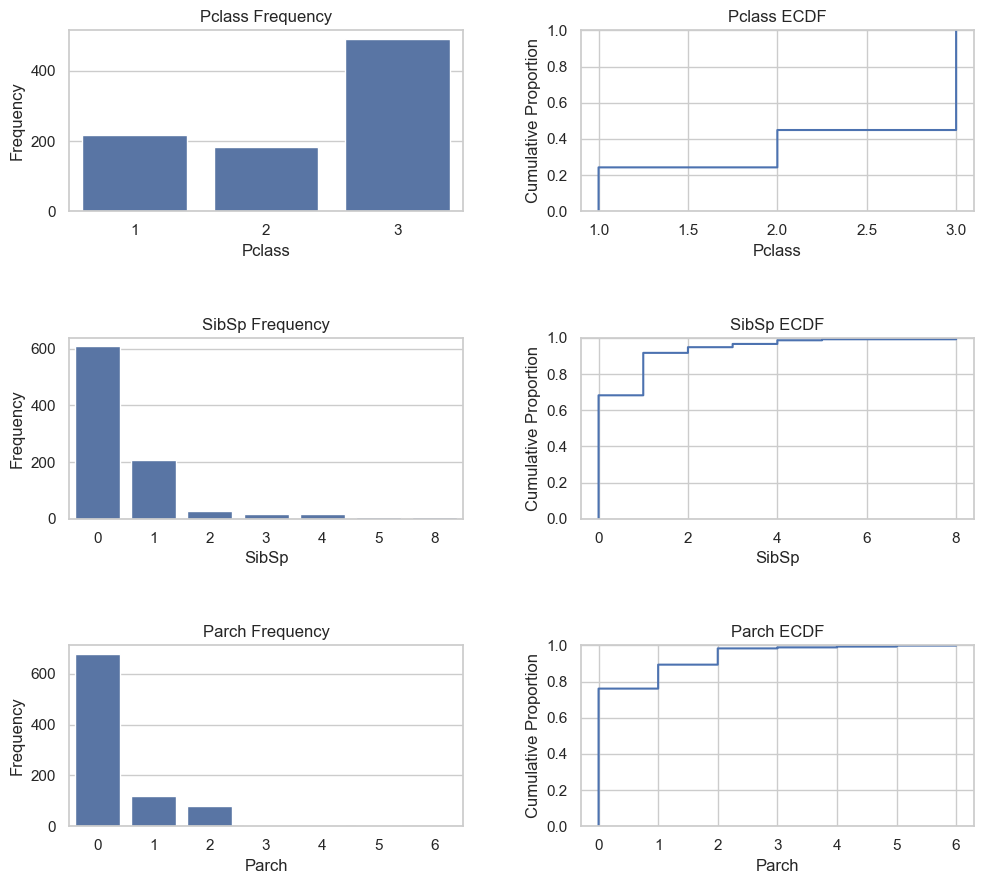

In [201]:
cols = 2
l = len(Discrete) * 2
rows = math.ceil(l / cols)

fig, axs = plt.subplots(rows, cols, figsize=(cols*5, rows*3))

axs = np.array(axs).flatten()

x = 0

for i in Discrete:

    # 1. Count / Bar Plot
    sns.countplot(x=i, data=df, ax=axs[x])
    axs[x].set_title(f"{i} Frequency")
    axs[x].set_xlabel(i)
    axs[x].set_ylabel("Frequency")

    x += 1

    # 2. ECDF Plot
    sns.ecdfplot(data=df, x=i, ax=axs[x])
    axs[x].set_title(f"{i} ECDF")
    axs[x].set_xlabel(i)
    axs[x].set_ylabel("Cumulative Proportion")

    x += 1

# Hide unused subplot spaces
for ax in axs[x:]:
    ax.axis("off")

plt.tight_layout()

plt.subplots_adjust(
    wspace=0.3,
    hspace=0.7
)

plt.show()


#### Continuous data

In [202]:
print(df[Continuous].describe())

              Age        Fare
count  714.000000  891.000000
mean    29.699118   32.204208
std     14.526497   49.693429
min      0.420000    0.000000
25%     20.125000    7.910400
50%     28.000000   14.454200
75%     38.000000   31.000000
max     80.000000  512.329200


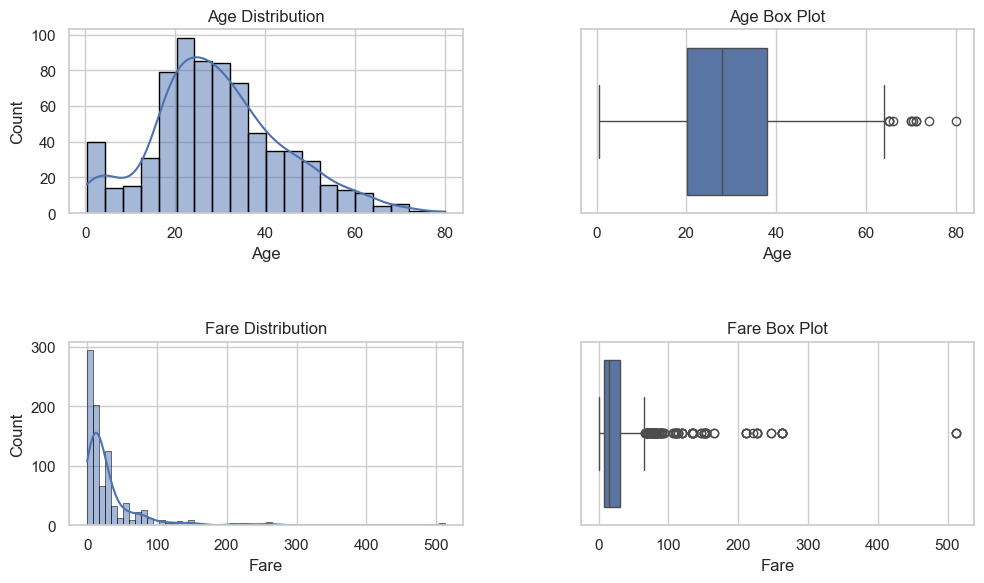

In [203]:
cols=2
l=len(Continuous)*2
rows=math.ceil(l/cols)

fig, axs = plt.subplots(rows,cols, figsize=(cols*5,rows*3)) #figsize(width,height)

axs = np.array(axs).flatten() # axs returns array only for 2d and more else return axes object

x=0
for i in Continuous:

    sns.histplot(df[i], kde=True, ax=axs[x], edgecolor="black")
    axs[x].set_title(f"{i} Distribution")

    x=x+1
    
    sns.boxplot(x=i,data=df,ax=axs[x])
    axs[x].set_title(f"{i} Box Plot")
    

    x+=1

for ax in axs[x:]:
    ax.axis("off") #ax assigns with graph space

plt.tight_layout()
plt.subplots_adjust(
    wspace=0.3,  # horizontal g
    hspace=0.7   # vertical gap
)


In [204]:
outlier_cols = ["Age", "Fare"]

## Bivariate Analysis

### Categorical features vs Target(Survived)

In [205]:
categorical_features = ["Pclass", "Sex", "SibSp", "Parch", "Embarked"]

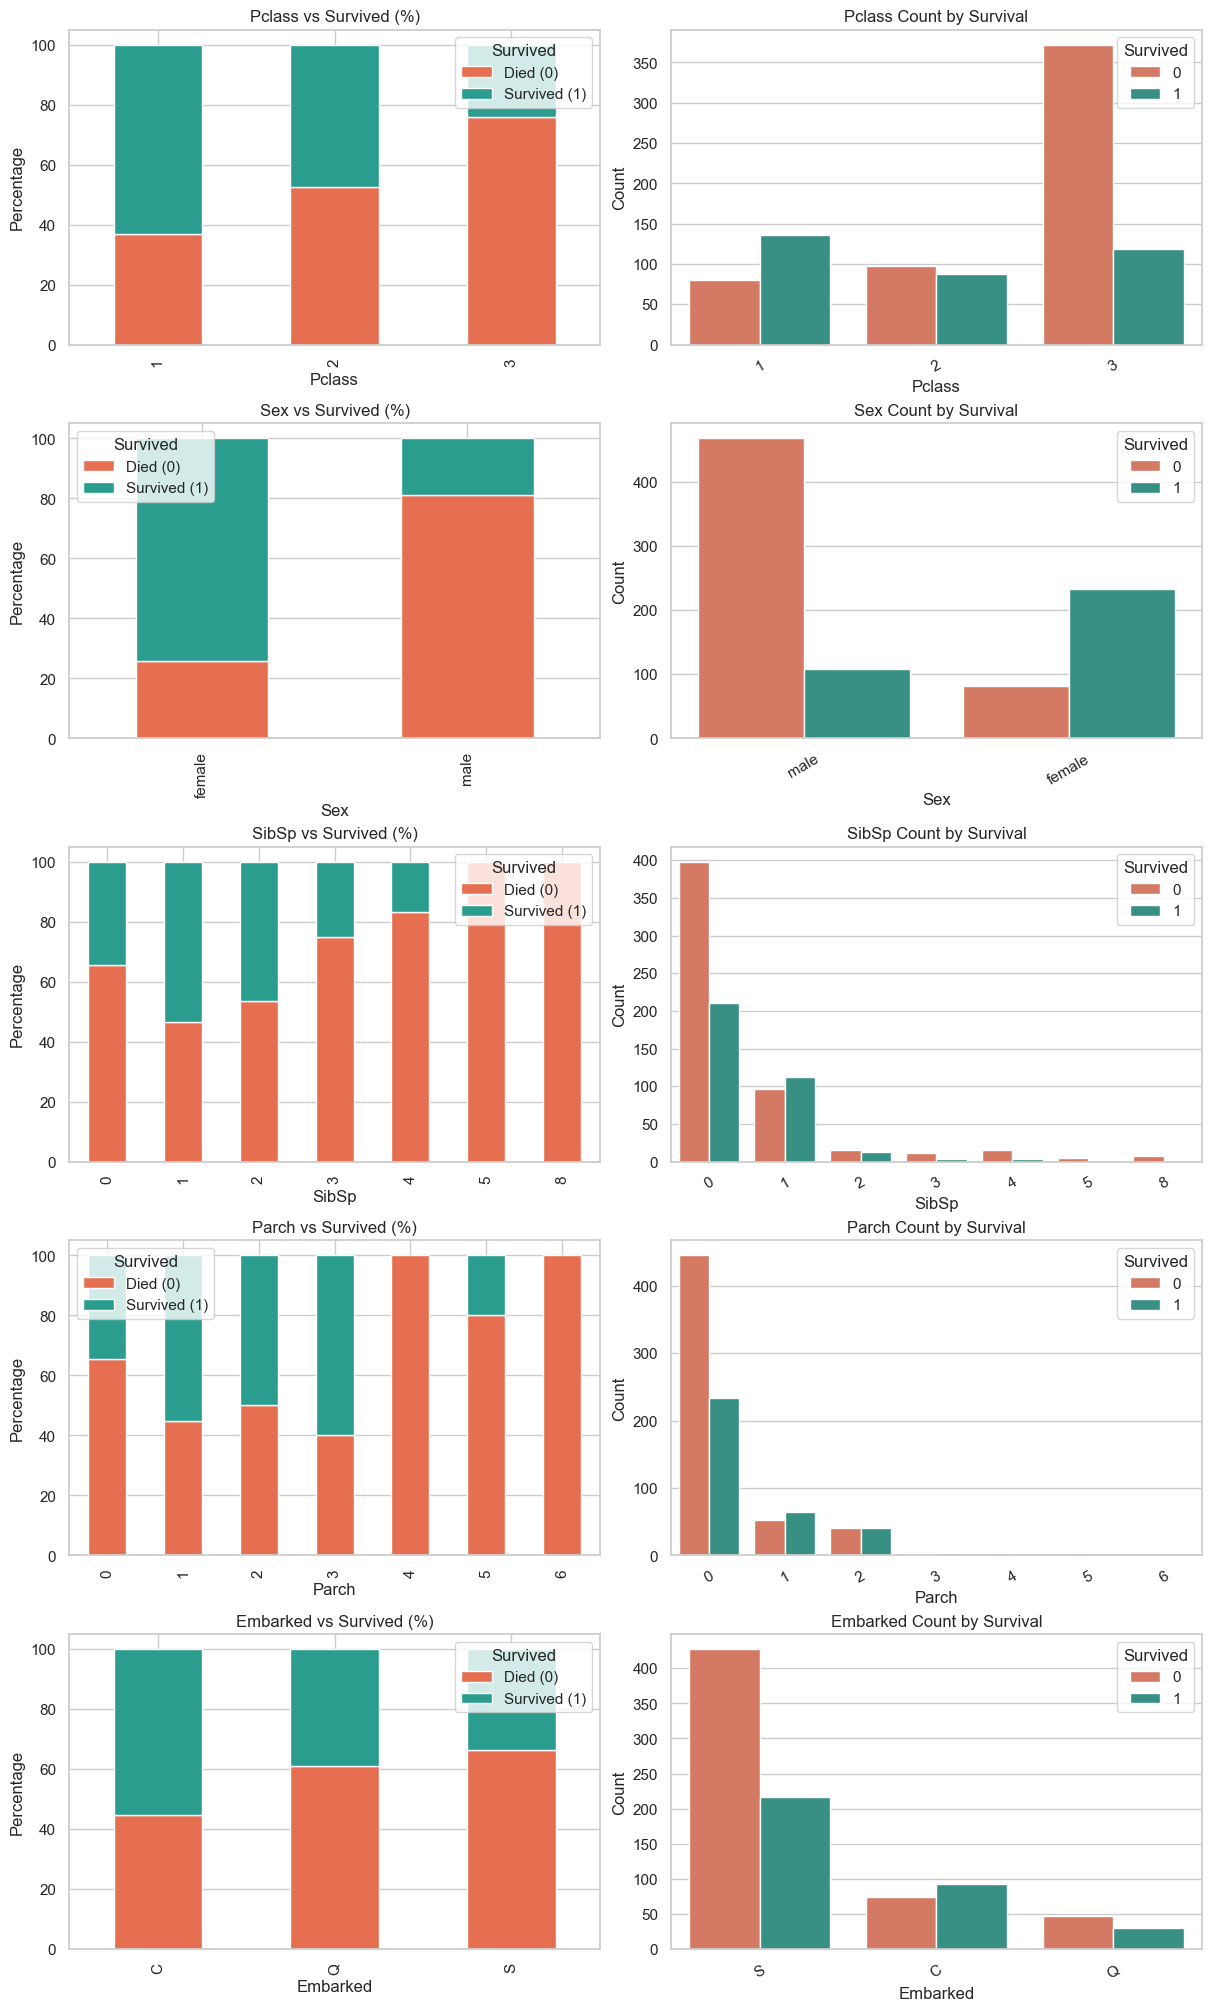

In [206]:
cols = 2
l = len(categorical_features) * 2
rows = math.ceil(l / cols)

sns.set_theme(style="whitegrid", font_scale=1.0)

fig, axs = plt.subplots(
    rows, cols,
    figsize=(cols * 6, rows * 4),
    constrained_layout=True
)

axs = np.atleast_1d(axs).flatten()
x = 0

for i in categorical_features:

    # 100% stacked bar chart
    percent = pd.crosstab(df[i], df["Survived"], normalize="index") * 100

    percent.plot(
        kind="bar",
        stacked=True,
        ax=axs[x],
        color=["#E76F51", "#2A9D8F"]
    )

    axs[x].set_title(f"{i} vs Survived (%)")
    axs[x].set_xlabel(i)
    axs[x].set_ylabel("Percentage")
    axs[x].legend(
        title="Survived",
        labels=["Died (0)", "Survived (1)"]
    )

    x += 1

    # Grouped count plot
    sns.countplot(
        data=df,
        x=i,
        hue="Survived",
        ax=axs[x],
        palette={0: "#E76F51", 1: "#2A9D8F"}
    )

    axs[x].set_title(f"{i} Count by Survival")
    axs[x].set_xlabel(i)
    axs[x].set_ylabel("Count")
    axs[x].tick_params(axis="x", rotation=30)

    x += 1

for ax in axs[x:]:
    ax.axis("off")

plt.show()

### Numerical features vs. Survived

In [207]:
numerical_features = ["Age", "Fare"]

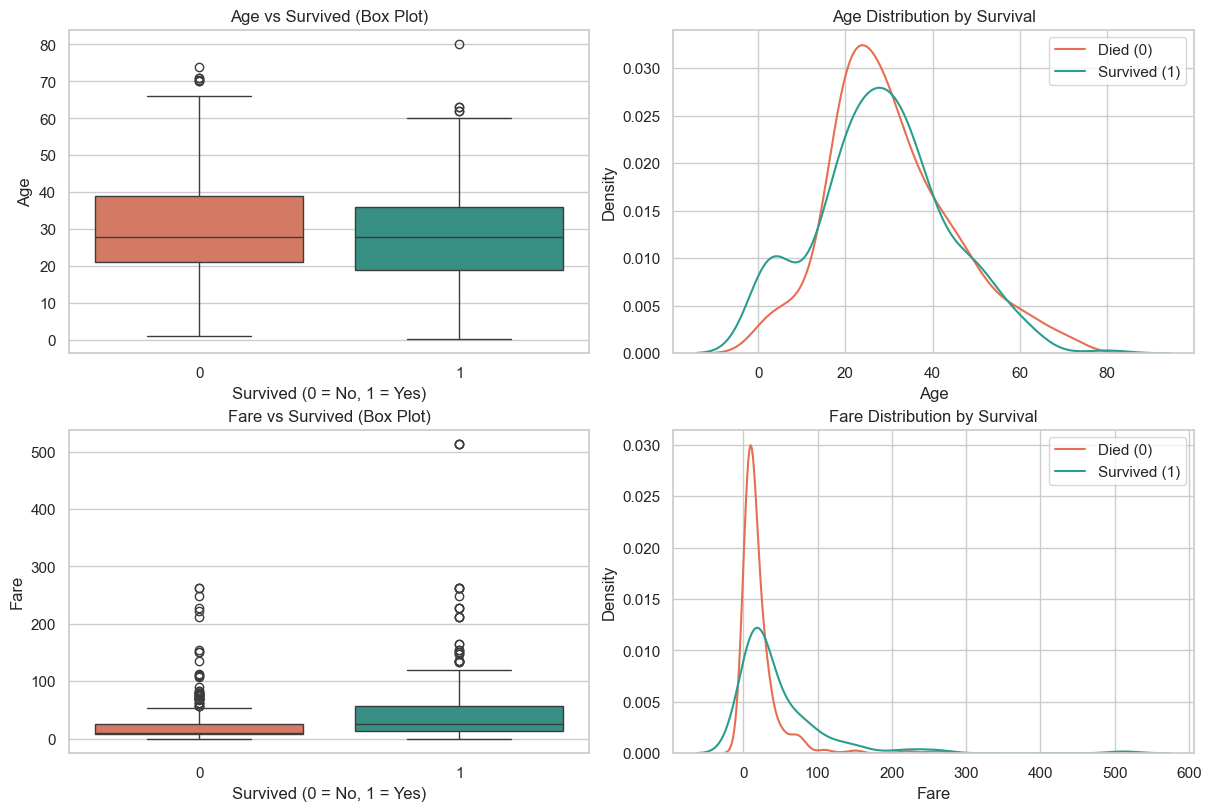

In [208]:
cols = 2
l = len(numerical_features) * 2
rows = math.ceil(l / cols)

sns.set_theme(style="whitegrid", font_scale=1.0)

fig, axs = plt.subplots(
    rows, cols,
    figsize=(cols * 6, rows * 4),
    constrained_layout=True
)

axs = np.atleast_1d(axs).flatten()
x = 0

for i in numerical_features:

    # Box plot
    sns.boxplot(
        data=df,
        x="Survived",
        y=i,
        hue="Survived",
        ax=axs[x],
        palette={0: "#E76F51", 1: "#2A9D8F"},
        legend=False
    )

    axs[x].set_title(f"{i} vs Survived (Box Plot)")
    axs[x].set_xlabel("Survived (0 = No, 1 = Yes)")
    axs[x].set_ylabel(i)

    x += 1

    # KDE plot
    for target_value, color, label in [
        (0, "#E76F51", "Died (0)"),
        (1, "#2A9D8F", "Survived (1)")
    ]:
        sns.kdeplot(
            data=df.loc[df["Survived"] == target_value],
            x=i,
            ax=axs[x],
            color=color,
            label=label
        )

    axs[x].set_title(f"{i} Distribution by Survival")
    axs[x].set_xlabel(i)
    axs[x].set_ylabel("Density")
    axs[x].legend()

    x += 1

for ax in axs[x:]:
    ax.axis("off")

plt.show()

## Correlation Analysis

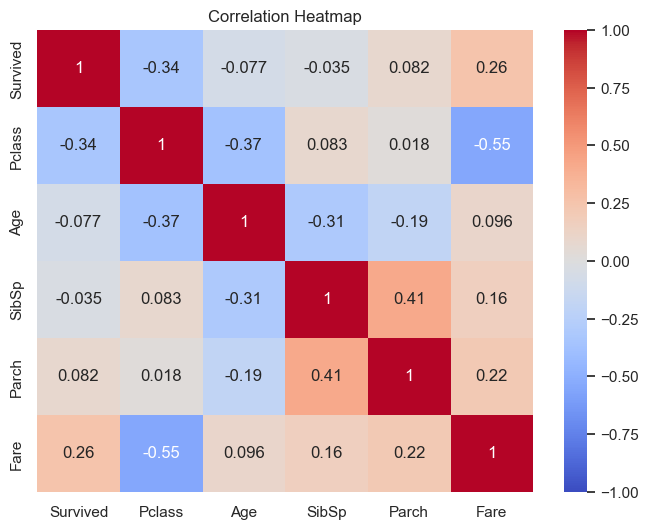

In [209]:
num_df = df.select_dtypes(include="number")

plt.figure(figsize=(8, 6))

sns.heatmap(
    num_df.corr(),
    annot=True,
    cmap="coolwarm",
    vmin=-1,
    vmax=1
)

plt.title("Correlation Heatmap")
plt.show()

# Data Splitting and Preprocessing

## Splitting

In [120]:
X = df.drop('Survived',axis=1)
y = df['Survived']

In [121]:
from sklearn.model_selection import train_test_split
X_train, X_val, y_train, y_val = train_test_split(X,
                                                  y,
                                                  test_size=0.20,
                                                  random_state=42,
                                                  stratify=y) 

In [122]:
print("Training set: ", X_train.shape, y_train.shape )
print("Testing set: ",  X_val.shape, y_val.shape)

Training set:  (712, 9) (712,)
Testing set:  (179, 9) (179,)


## Null Values Handling

In [123]:
from sklearn.impute import SimpleImputer

In [124]:
print(X_train.isna().sum())
print(X_val.isna().sum())

Pclass           0
Sex              0
Age            137
SibSp            0
Parch            0
Fare             0
Embarked         2
Cabin_Deck       0
Name_Titles      0
dtype: int64
Pclass          0
Sex             0
Age            40
SibSp           0
Parch           0
Fare            0
Embarked        0
Cabin_Deck      0
Name_Titles     0
dtype: int64


In [125]:
groups = X_train.groupby('Name_Titles')['Age'].median()
X_train['Age'] = X_train['Age'].fillna(X_train['Name_Titles'].map(groups))
X_val['Age'] = X_val['Age'].fillna(X_val['Name_Titles'].map(groups))

X_train['Age'] = X_train['Age'].fillna(X_train['Age'].median())
X_val['Age'] = X_val['Age'].fillna(X_train['Age'].median())

In [126]:
ModeImputer = SimpleImputer(strategy = 'most_frequent')
MeanImputer = SimpleImputer(strategy = 'mean')

In [127]:
X_train[['Embarked']] = ModeImputer.fit_transform(X_train[['Embarked']])
X_val[['Embarked']] = ModeImputer.transform(X_val[['Embarked']])

In [128]:
print(X_train.isna().sum().sum())
print(X_val.isna().sum().sum())

0
0


## Encoding

In [129]:
from sklearn.preprocessing import OneHotEncoder, OrdinalEncoder,  LabelEncoder

In [130]:
col_sep(X_train)

(['Pclass', 'Age', 'SibSp', 'Parch', 'Fare'],
 ['Sex', 'Embarked', 'Cabin_Deck', 'Name_Titles'])

In [131]:
categorical_cols = ['Sex', 'Embarked', 'Cabin_Deck', 'Name_Titles']

In [132]:
X_train[categorical_cols].nunique()

Sex             2
Embarked        3
Cabin_Deck      9
Name_Titles    14
dtype: int64

In [133]:
rare_threshold = 10

for col in ['Cabin_Deck', 'Name_Titles']:
    counts = X_train[col].value_counts()
    rare_categories = counts[counts < rare_threshold].index

    X_train[col] = X_train[col].replace(rare_categories, 'RARE')
    X_val[col] = X_val[col].replace(rare_categories, 'RARE')

In [134]:
X_train[categorical_cols].nunique()

Sex            2
Embarked       3
Cabin_Deck     8
Name_Titles    5
dtype: int64

In [135]:
oe = OneHotEncoder(
    sparse_output=False,
    handle_unknown="ignore"
).set_output(transform="pandas")

In [136]:
X_train_encoded = oe.fit_transform(X_train[categorical_cols])
X_val_encoded = oe.transform(X_val[categorical_cols])

# Remove original categorical columns and add encoded columns
X_train = pd.concat([X_train.drop(columns=categorical_cols, errors="ignore"), X_train_encoded], axis=1)

X_val = pd.concat([X_val.drop(columns=categorical_cols, errors="ignore"), X_val_encoded], axis=1)


## X_train_scaled - for distance based models

In [137]:
#For outlier handling for distance based algorithms

X_train_scaled = X_train.copy()
X_val_scaled = X_val.copy()

In [138]:
from sklearn.preprocessing import StandardScaler, MinMaxScaler

In [139]:
outlier_cols

['Age', 'Fare']

In [140]:
for  i in outlier_cols:
    X_train_scaled[i] = np.log1p(X_train_scaled[i])
    X_val_scaled[i] = np.log1p(X_val_scaled[i])

In [141]:
scaler_scaled = StandardScaler()
for col in outlier_cols:

    X_train_scaled[[col]] = scaler_scaled.fit_transform(X_train_scaled[[col]])
    
    X_val_scaled[[col]] = scaler_scaled.transform(X_val_scaled[[col]])

## Final Check

In [142]:

assert X_train.columns.equals(X_val.columns)

assert y_train.notna().all()
assert y_val.notna().all()

assert len(X_train.index.intersection(X_val.index)) == 0

print("Training rows:", len(X_train))
print("Validation rows:", len(X_val))

Training rows: 712
Validation rows: 179


# Model Training and validation

In [143]:
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report
)

## Logistic Regression

In [144]:
lr = LogisticRegression(max_iter=1000, random_state=42)

lr.fit(X_train_scaled, y_train)

,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add a L2 penalty term and it is the default choice;- `'l1'`: add a L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'` and `l1_ratio` set to any float between 0 and 1 for `'penalty='elasticnet'`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some penalties, may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionchanged:: 1.8 Default value changed from None to 0.0... deprecated:: 1.8 `None` is deprecated and will be removed in version 1.10. Always use `l1_ratio` to specify the penalty type.",0.0
,"dual dual: bool, default=FalseDual (constrained) or primal (regularized, see also:ref:`this equation `) formulation. Dual formulationis only implemented for l2 penalty with liblinear solver. Prefer `dual=False`when n_samples > n_features.",False
,"tol tol: float, default=1e-4Tolerance for stopping criteria.",0.0001
,"fit_intercept fit_intercept: bool, default=TrueSpecifies if a constant (a.k.a. bias or intercept) should beadded to the decision function.",True
,"intercept_scaling intercept_scaling: float, default=1Useful only when the solver `liblinear` is usedand `self.fit_intercept` is set to `True`. In this case, `x` becomes`[x, self.intercept_scaling]`,i.e. a ""synthetic"" feature with constant value equal to`intercept_scaling` is appended to the instance vector.The intercept becomes``intercept_scaling * synthetic_feature_weight``... note:: The synthetic feature weight is subject to L1 or L2 regularization as all other features. To lessen the effect of regularization on synthetic feature weight (and therefore on the intercept) `intercept_scaling` has to be increased.",1
,"class_weight class_weight: dict or 'balanced', default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified... versionadded:: 0.17 *class_weight='balanced'*",None
,"random_state random_state: int, RandomState instance, default=NoneUsed when ``solver`` == 'sag', 'saga' or 'liblinear' to shuffle thedata. See :term:`Glossary ` for details.",42
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use in the optimization problem. Default is 'lbfgs'.To choose a solver, you might want to consider the following aspects:- 'lbfgs' is a good default solver because it works reasonably well for a wide class of problems.- For :term:`multi

In [145]:
print("Training Results:")
print(classification_report(y_train, lr.predict(X_train_scaled)))

y_pred_lr = lr.predict(X_val_scaled)

print("Validation Results:")
print(classification_report(y_val, y_pred_lr))

Training Results:
              precision    recall  f1-score   support

           0       0.86      0.88      0.87       439
           1       0.80      0.77      0.79       273

    accuracy                           0.84       712
   macro avg       0.83      0.83      0.83       712
weighted avg       0.84      0.84      0.84       712

Validation Results:
              precision    recall  f1-score   support

           0       0.84      0.88      0.86       110
           1       0.80      0.74      0.77        69

    accuracy                           0.83       179
   macro avg       0.82      0.81      0.81       179
weighted avg       0.83      0.83      0.83       179



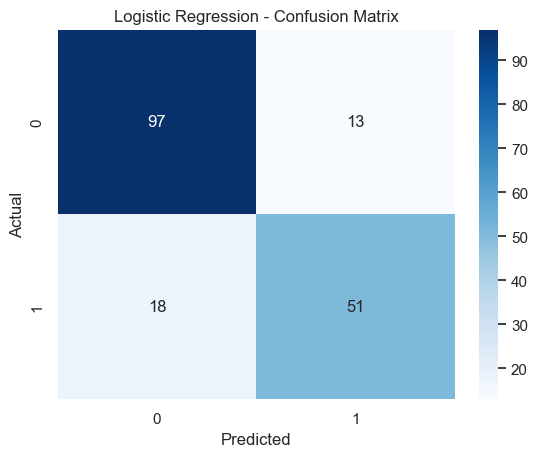

Accuracy : 0.8268156424581006
Precision: 0.796875
Recall   : 0.7391304347826086
F1 Score : 0.7669172932330827


In [146]:
cm = confusion_matrix(y_val, y_pred_lr)

sns.heatmap(cm, annot=True, fmt="d", cmap="Blues")
plt.title("Logistic Regression - Confusion Matrix")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.show()


print("Accuracy :", accuracy_score(y_val, y_pred_lr))
print("Precision:", precision_score(y_val, y_pred_lr))
print("Recall   :", recall_score(y_val, y_pred_lr))
print("F1 Score :", f1_score(y_val, y_pred_lr))

## Decision Tree

In [147]:
dt = DecisionTreeClassifier(min_samples_leaf=20)

dt.fit(X_train, y_train)

,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.",'gini'
,"splitter splitter: {""best"", ""random""}, default=""best""The strategy used to choose the split at each node. Supportedstrategies are ""best"" to choose the best split and ""random"" to choosethe best random split.",'best'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",20
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: int, float or {""sqrt"", ""log2""}, default=NoneThe number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`... note:: The search for a split does not stop until at least one valid partition of the node samples is found, even if it requires to effectively inspect more than ``max_features`` features.",None
,"random_state random_state: int, RandomState instance or None, default=NoneControls the randomness of the estimator. The features are alwaysrandomly permuted at each split, even if ``splitter`` is set to``""best""``. When ``max_features < n_features``, the algorithm willselect ``max_features`` at random at each split before finding the bestsplit among them. But the best found split may vary across differentruns, even if ``max_features=n_features``. That is the case, if theimprovement of the criterion is identical for several splits and onesplit has to be selected at random. To obtain a deterministic behaviourduring fitting, ``random_state`` has to be fixed to an integer.See :term:`Glossary ` for details.",None
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow a tree with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsamples at the curr

First model<br>
accuracy was 0.99 on training and
accuracy was 0.81 on testing <br>
overfitting condition so adjust the parameter min_samples_leaf=20

In [148]:
print("Training Results:")
print(classification_report(y_train, dt.predict(X_train)))


y_pred_tree = dt.predict(X_val)
print("Validation Results:")
print(classification_report(y_val,y_pred_tree ))

Training Results:
              precision    recall  f1-score   support

           0       0.84      0.91      0.87       439
           1       0.83      0.71      0.77       273

    accuracy                           0.83       712
   macro avg       0.83      0.81      0.82       712
weighted avg       0.83      0.83      0.83       712

Validation Results:
              precision    recall  f1-score   support

           0       0.82      0.91      0.86       110
           1       0.82      0.68      0.75        69

    accuracy                           0.82       179
   macro avg       0.82      0.80      0.80       179
weighted avg       0.82      0.82      0.82       179



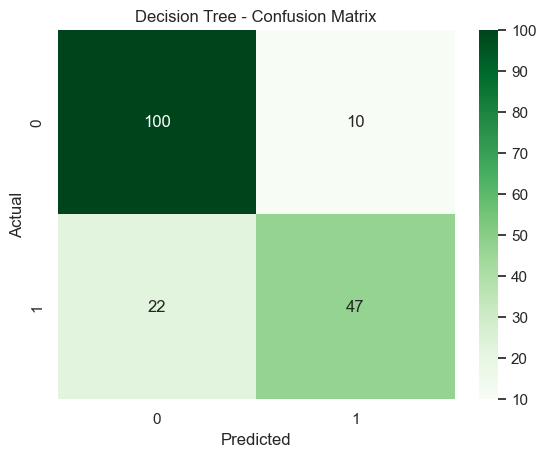

Accuracy : 0.8212290502793296
Precision: 0.8245614035087719
Recall   : 0.6811594202898551
F1 Score : 0.746031746031746


In [149]:
cm = confusion_matrix(y_val, y_pred_tree)

sns.heatmap(cm, annot=True, fmt="d", cmap="Greens")
plt.title("Decision Tree - Confusion Matrix")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.show()



print("Accuracy :", accuracy_score(y_val, y_pred_tree))
print("Precision:", precision_score(y_val, y_pred_tree))
print("Recall   :", recall_score(y_val, y_pred_tree))
print("F1 Score :", f1_score(y_val, y_pred_tree))

## Random Forest

In [150]:
rf = RandomForestClassifier(    
    min_samples_split=10,
    min_samples_leaf=5,
    random_state=0
)

rf.fit(X_train, y_train)

,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",100
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.Note: This parameter is tree-specific.",'gini'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",10
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",5
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=""sqrt""The number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`... versionchanged:: 1.1 The default of `max_features` changed from `""auto""` to `""sqrt""`.Note: the search for a split does not stop until at least onevalid partition of the node samples is found, even if it requires toeffectively inspect more than ``max_features`` features.",'sqrt'
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow trees with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsamples at the current node, ``N_t_L`` is the number of samples in theleft child, and ``N_t_R`` is the number of samples in the right child.``N``, ``N_t``, ``N_t_R`` and ``N_t_L`` all refer to the weighted sum,if ``sample_weight`` is passed... versionadded:: 0.19",0.0
,"bootstrap bootstrap: bool, default=TrueWhether bootstrap samples are used when building trees. If False, thewhole dataset is used to build each tree.",True
,"oob_score oob_score: bool or callable, default=FalseWhether to use out-of-bag samples to estimate the generalization score.By default, :func:`~sklearn.metrics.accuracy_score` is used.Provide a callable with signature `metri

Default model<br>
accuracy was 0.99 on training and
accuracy was 0.80 on testing <br>
overfitting condition so adjust the hyper parameter

In [151]:
print("Training Results:")
print(classification_report(y_train, rf.predict(X_train)))


y_pred_rf = rf.predict(X_val)
print("Validation Results:")
print(classification_report(y_val,y_pred_rf))

Training Results:
              precision    recall  f1-score   support

           0       0.86      0.94      0.90       439
           1       0.88      0.75      0.81       273

    accuracy                           0.87       712
   macro avg       0.87      0.84      0.85       712
weighted avg       0.87      0.87      0.86       712

Validation Results:
              precision    recall  f1-score   support

           0       0.83      0.91      0.87       110
           1       0.83      0.71      0.77        69

    accuracy                           0.83       179
   macro avg       0.83      0.81      0.82       179
weighted avg       0.83      0.83      0.83       179



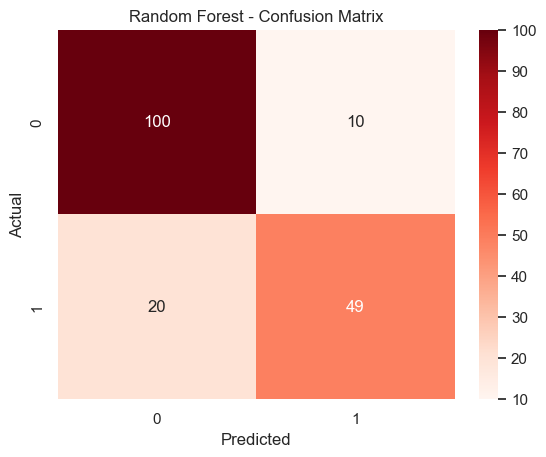

Accuracy : 0.8324022346368715
Precision: 0.8305084745762712
Recall   : 0.7101449275362319
F1 Score : 0.765625


In [152]:
cm = confusion_matrix(y_val, y_pred_rf)

sns.heatmap(cm, annot=True, fmt="d", cmap="Reds")
plt.title("Random Forest - Confusion Matrix")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.show()



print("Accuracy :", accuracy_score(y_val, y_pred_rf))
print("Precision:", precision_score(y_val, y_pred_rf))
print("Recall   :", recall_score(y_val, y_pred_rf))
print("F1 Score :", f1_score(y_val, y_pred_rf))

# Final Model Training and Test Predictions

## Preprocessing

In [153]:
X_full = X.copy()
y_full = y

In [154]:
X_test = pd.read_csv(r"Data/test.csv")
test_passenger_ids = X_test["PassengerId"].copy()

In [155]:
print(X_full.columns)
print(X_test.columns)

Index(['Pclass', 'Sex', 'Age', 'SibSp', 'Parch', 'Fare', 'Embarked',
       'Cabin_Deck', 'Name_Titles'],
      dtype='object')
Index(['PassengerId', 'Pclass', 'Name', 'Sex', 'Age', 'SibSp', 'Parch',
       'Ticket', 'Fare', 'Cabin', 'Embarked'],
      dtype='object')


In [156]:
X_test['Cabin_Deck'] = X_test['Cabin'].str[0].fillna('NoCabin')
X_test['Name_Titles'] = X_test['Name'].str.split(",").str[1].str.split(".").str[0].str.strip()
X_test = X_test.drop(columns=['PassengerId', 'Ticket',  'Name', 'Cabin'])

In [157]:
X_full.columns.equals(X_test.columns)

True

In [158]:
print(X_full.isna().sum(),"\n")
print(X_test.isna().sum())

Pclass           0
Sex              0
Age            177
SibSp            0
Parch            0
Fare             0
Embarked         2
Cabin_Deck       0
Name_Titles      0
dtype: int64 

Pclass          0
Sex             0
Age            86
SibSp           0
Parch           0
Fare            1
Embarked        0
Cabin_Deck      0
Name_Titles     0
dtype: int64


In [159]:
# NUll VALUES
groups = X_full.groupby('Name_Titles')['Age'].median()

X_full['Age'] = X_full['Age'].fillna(X_full['Name_Titles'].map(groups))
X_test['Age'] = X_test['Age'].fillna(X_test['Name_Titles'].map(groups))

X_full['Age'] = X_full['Age'].fillna(X_full['Age'].median())
X_test['Age'] = X_test['Age'].fillna(X_full['Age'].median())


X_full[['Embarked']] = ModeImputer.fit_transform(X_full[['Embarked']])


MeanImputer.fit(X_full[['Fare']])
X_test[['Fare']] = MeanImputer.transform(X_test[['Fare']])

In [160]:
categorical_cols

['Sex', 'Embarked', 'Cabin_Deck', 'Name_Titles']

In [161]:
rare_threshold = 10

for col in ['Cabin_Deck', 'Name_Titles']:
    counts = X_full[col].value_counts()
    rare_categories = counts[counts < rare_threshold].index

    X_full[col] = X_full[col].replace(rare_categories, 'RARE')
    X_test[col] = X_test[col].replace(rare_categories, 'RARE')

In [162]:
## ENCODING
X_full_encoded = oe.fit_transform(X_full[categorical_cols])
X_test_encoded = oe.transform(X_test[categorical_cols])

X_full = pd.concat([X_full.drop(columns=categorical_cols), X_full_encoded], axis=1)
X_test = pd.concat([X_test.drop(columns=categorical_cols), X_test_encoded], axis=1)

In [163]:
X_full.columns.equals(X_test.columns)

True

#### Outlier handling for distance based algorithms

In [164]:
X_full_scaled = X_full.copy()
X_test_scaled = X_test.copy()

In [165]:
from sklearn.preprocessing import StandardScaler
scaler_scaled = StandardScaler()

In [166]:
outlier_cols

['Age', 'Fare']

In [167]:
for  i in outlier_cols:
    X_full_scaled[i] = np.log1p(X_full_scaled[i])
    X_test_scaled[i] = np.log1p(X_test_scaled[i])


for col in outlier_cols:

    X_full_scaled[[col]] = scaler_scaled.fit_transform(X_full_scaled[[col]])
    
    X_test_scaled[[col]] = scaler_scaled.transform(X_test_scaled[[col]])

### Final Check

In [168]:

assert X_full.columns.equals(X_test.columns)


assert y_full.notna().all()


print("Training rows:", len(X_full))
print("Validation rows:", len(X_test))

Training rows: 891
Validation rows: 418


# Models

## Logistic Regression

In [169]:
lr.fit(X_full_scaled,y_full)

,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add a L2 penalty term and it is the default choice;- `'l1'`: add a L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'` and `l1_ratio` set to any float between 0 and 1 for `'penalty='elasticnet'`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some penalties, may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionchanged:: 1.8 Default value changed from None to 0.0... deprecated:: 1.8 `None` is deprecated and will be removed in version 1.10. Always use `l1_ratio` to specify the penalty type.",0.0
,"dual dual: bool, default=FalseDual (constrained) or primal (regularized, see also:ref:`this equation `) formulation. Dual formulationis only implemented for l2 penalty with liblinear solver. Prefer `dual=False`when n_samples > n_features.",False
,"tol tol: float, default=1e-4Tolerance for stopping criteria.",0.0001
,"fit_intercept fit_intercept: bool, default=TrueSpecifies if a constant (a.k.a. bias or intercept) should beadded to the decision function.",True
,"intercept_scaling intercept_scaling: float, default=1Useful only when the solver `liblinear` is usedand `self.fit_intercept` is set to `True`. In this case, `x` becomes`[x, self.intercept_scaling]`,i.e. a ""synthetic"" feature with constant value equal to`intercept_scaling` is appended to the instance vector.The intercept becomes``intercept_scaling * synthetic_feature_weight``... note:: The synthetic feature weight is subject to L1 or L2 regularization as all other features. To lessen the effect of regularization on synthetic feature weight (and therefore on the intercept) `intercept_scaling` has to be increased.",1
,"class_weight class_weight: dict or 'balanced', default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified... versionadded:: 0.17 *class_weight='balanced'*",None
,"random_state random_state: int, RandomState instance, default=NoneUsed when ``solver`` == 'sag', 'saga' or 'liblinear' to shuffle thedata. See :term:`Glossary ` for details.",42
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use in the optimization problem. Default is 'lbfgs'.To choose a solver, you might want to consider the following aspects:- 'lbfgs' is a good default solver because it works reasonably well for a wide class of problems.- For :term:`multi

In [170]:
print("Training Results:")
print(classification_report(y_full, lr.predict(X_full_scaled)))

Training Results:
              precision    recall  f1-score   support

           0       0.86      0.89      0.87       549
           1       0.81      0.77      0.79       342

    accuracy                           0.84       891
   macro avg       0.83      0.83      0.83       891
weighted avg       0.84      0.84      0.84       891



In [171]:
y_pred_lr = lr.predict(X_test_scaled)

In [172]:
submission = pd.DataFrame({
    'PassengerId': test_passenger_ids,
    'Survived': y_pred_lr
})

submission.to_csv('LogisticSubmission.csv', index=False)

## Decision Tree

In [173]:
dt.fit(X_full,y_full)

,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.",'gini'
,"splitter splitter: {""best"", ""random""}, default=""best""The strategy used to choose the split at each node. Supportedstrategies are ""best"" to choose the best split and ""random"" to choosethe best random split.",'best'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",20
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: int, float or {""sqrt"", ""log2""}, default=NoneThe number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`... note:: The search for a split does not stop until at least one valid partition of the node samples is found, even if it requires to effectively inspect more than ``max_features`` features.",None
,"random_state random_state: int, RandomState instance or None, default=NoneControls the randomness of the estimator. The features are alwaysrandomly permuted at each split, even if ``splitter`` is set to``""best""``. When ``max_features < n_features``, the algorithm willselect ``max_features`` at random at each split before finding the bestsplit among them. But the best found split may vary across differentruns, even if ``max_features=n_features``. That is the case, if theimprovement of the criterion is identical for several splits and onesplit has to be selected at random. To obtain a deterministic behaviourduring fitting, ``random_state`` has to be fixed to an integer.See :term:`Glossary ` for details.",None
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow a tree with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsamples at the curr

In [174]:
print("Training Results:")
print(classification_report(y_full, dt.predict(X_full)))

Training Results:
              precision    recall  f1-score   support

           0       0.84      0.92      0.88       549
           1       0.85      0.73      0.79       342

    accuracy                           0.85       891
   macro avg       0.85      0.82      0.83       891
weighted avg       0.85      0.85      0.84       891



In [175]:
y_pred_tree = dt.predict(X_test)

In [176]:
submission = pd.DataFrame({
    'PassengerId': test_passenger_ids,
    'Survived': y_pred_tree
})

submission.to_csv('TreeSubmission.csv', index=False)

## Random forest

In [177]:
rf.fit(X_full, y_full)

,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",100
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.Note: This parameter is tree-specific.",'gini'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",10
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",5
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=""sqrt""The number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`... versionchanged:: 1.1 The default of `max_features` changed from `""auto""` to `""sqrt""`.Note: the search for a split does not stop until at least onevalid partition of the node samples is found, even if it requires toeffectively inspect more than ``max_features`` features.",'sqrt'
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow trees with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsamples at the current node, ``N_t_L`` is the number of samples in theleft child, and ``N_t_R`` is the number of samples in the right child.``N``, ``N_t``, ``N_t_R`` and ``N_t_L`` all refer to the weighted sum,if ``sample_weight`` is passed... versionadded:: 0.19",0.0
,"bootstrap bootstrap: bool, default=TrueWhether bootstrap samples are used when building trees. If False, thewhole dataset is used to build each tree.",True
,"oob_score oob_score: bool or callable, default=FalseWhether to use out-of-bag samples to estimate the generalization score.By default, :func:`~sklearn.metrics.accuracy_score` is used.Provide a callable with signature `metri

In [178]:
print("Training Results:")
print(classification_report(y_full, rf.predict(X_full)))

Training Results:
              precision    recall  f1-score   support

           0       0.85      0.93      0.89       549
           1       0.87      0.75      0.80       342

    accuracy                           0.86       891
   macro avg       0.86      0.84      0.85       891
weighted avg       0.86      0.86      0.86       891



In [179]:
y_pred_rf = rf.predict(X_test)

In [180]:
submission = pd.DataFrame({
    'PassengerId': test_passenger_ids,
    'Survived': y_pred_rf
})

submission.to_csv('RandomForestSubmission.csv', index=False)